# ASL TCN — Results and Evaluation

**Project:** Hi-Five — Dynamic Isolated Sign Language Recognition  
**Dataset:** ASL Citizen (Selected 105 Classes)  
**Model:** Temporal Convolutional Network (TCN)  
**Features:** 302-dim MediaPipe landmarks per frame, 64-frame sequences  
**Evaluation:** Signer-independent test set


In [2]:
import csv
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
from collections import defaultdict

import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# Add project root to path
PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Output folder for all generated files
OUTPUT_DIR = PROJECT_ROOT / 'results/asl'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

from training.tcn import SignTCN

# Paths
FEATURES_DIR  = PROJECT_ROOT / 'data/ASL-Citizen/features'
TEST_DIR      = FEATURES_DIR / 'test'
TEST_MANIFEST = FEATURES_DIR / 'test_manifest.csv'
LABEL_MAP     = PROJECT_ROOT / 'models/asl_label_map.csv'
MODEL_PATH    = PROJECT_ROOT / 'models/asl_tcn.pth'
SPLITS_DIR    = PROJECT_ROOT / 'data/ASL-Citizen/splits'
TRAINING_LOG  = PROJECT_ROOT / 'models/asl_training_log.csv'

BATCH_SIZE = 32
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
print(f'Model: {MODEL_PATH}')


Device: cpu
Model: c:\Users\Vincent\Downloads\Hi-Five\Hi-Five_Recognition\ml\models\asl_tcn.pth


## 1. Dataset Overview

In [32]:
# Load manifests
train_manifest = pd.read_csv(FEATURES_DIR / 'train_manifest.csv')
val_manifest   = pd.read_csv(FEATURES_DIR / 'val_manifest.csv')
test_manifest  = pd.read_csv(FEATURES_DIR / 'test_manifest.csv')
label_map_df   = pd.read_csv(LABEL_MAP)

print('=' * 50)
print('ASL CITIZEN — SELECTED 105 CLASSES')
print('=' * 50)
print(f'  Total classes   : {len(label_map_df)}')
print(f'  Train sequences : {len(train_manifest)}')
print(f'  Val sequences   : {len(val_manifest)}')
print(f'  Test sequences  : {len(test_manifest)}')
print(f'  Total sequences : {len(train_manifest) + len(val_manifest) + len(test_manifest)}')
print(f'\n  Train participants : {train_manifest["participant"].nunique()}')
print(f'  Val participants   : {val_manifest["participant"].nunique()}')
print(f'  Test participants  : {test_manifest["participant"].nunique()}')
print(f'\n  Feature shape : (64, 302)')
print(f'  Sequence length : 64 frames')
print(f'  Features/frame  : 302')


ASL CITIZEN — SELECTED 105 CLASSES
  Total classes   : 105
  Train sequences : 1775
  Val sequences   : 429
  Test sequences  : 1446
  Total sequences : 3650

  Train participants : 31
  Val participants   : 5
  Test participants  : 11

  Feature shape : (64, 302)
  Sequence length : 64 frames
  Features/frame  : 302


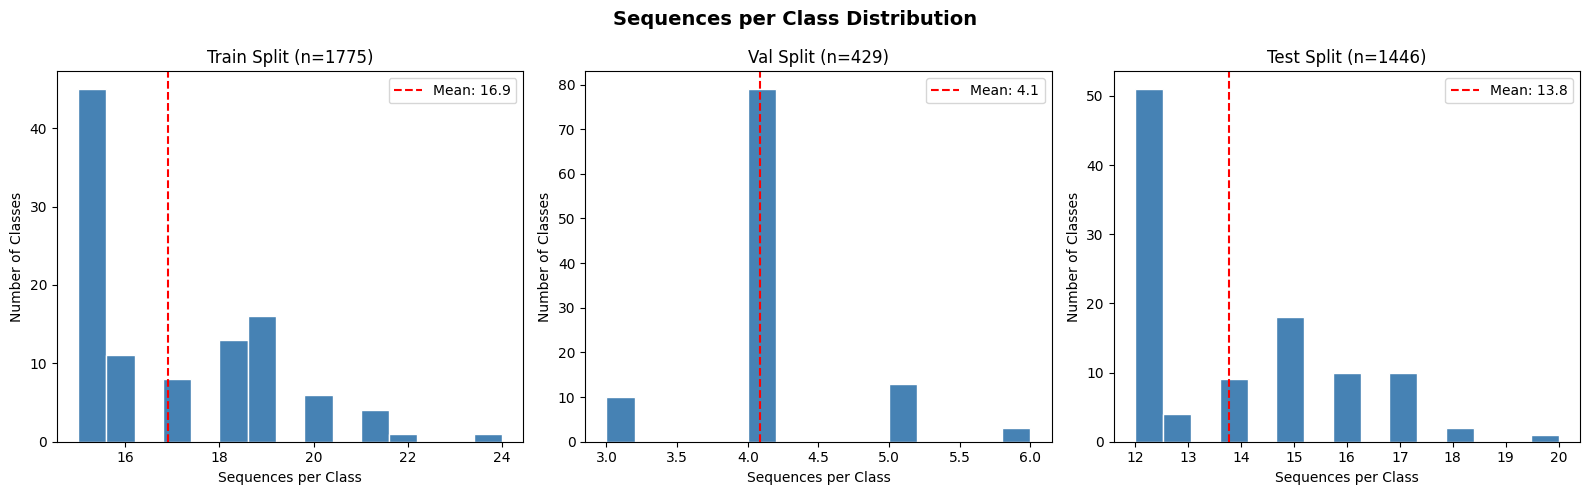

Train — min: 15 max: 24 avg: 16.9
Val   — min: 3 max: 6 avg: 4.1
Test  — min: 12 max: 20 avg: 13.8


In [33]:
# Sequences per class distribution
train_counts = train_manifest['gloss'].value_counts().sort_values()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Sequences per Class Distribution', fontsize=14, fontweight='bold')

for ax, manifest, split in zip(axes,
    [train_manifest, val_manifest, test_manifest],
    ['Train', 'Val', 'Test']):
    counts = manifest['gloss'].value_counts()
    ax.hist(counts.values, bins=15, color='steelblue', edgecolor='white')
    ax.set_title(f'{split} Split (n={len(manifest)})')
    ax.set_xlabel('Sequences per Class')
    ax.set_ylabel('Number of Classes')
    ax.axvline(counts.mean(), color='red', linestyle='--',
               label=f'Mean: {counts.mean():.1f}')
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR/'asl_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Train — min: {train_manifest["gloss"].value_counts().min()} max: {train_manifest["gloss"].value_counts().max()} avg: {train_manifest["gloss"].value_counts().mean():.1f}')
print(f'Val   — min: {val_manifest["gloss"].value_counts().min()} max: {val_manifest["gloss"].value_counts().max()} avg: {val_manifest["gloss"].value_counts().mean():.1f}')
print(f'Test  — min: {test_manifest["gloss"].value_counts().min()} max: {test_manifest["gloss"].value_counts().max()} avg: {test_manifest["gloss"].value_counts().mean():.1f}')


## 2. Model Architecture

In [34]:
# Load model
checkpoint = torch.load(MODEL_PATH, map_location=device)

model = SignTCN(
    feature_dim=checkpoint['feature_dim'],
    num_classes=checkpoint['num_classes'],
    channels=checkpoint['channels'],
    dilations=checkpoint['dilations'],
    kernel_size=checkpoint['kernel_size'],
    dropout=checkpoint['dropout'],
    fc_dropout=checkpoint['fc_dropout'],
).to(device)
model.load_state_dict(checkpoint['model_state'])
model.eval()

print('=' * 50)
print('MODEL ARCHITECTURE')
print('=' * 50)
print(f'  Architecture     : Temporal Convolutional Network (TCN)')
print(f'  Input shape      : (batch, 64, 302)')
print(f'  TCN blocks       : {len(checkpoint["channels"])}')
print(f'  Channels         : {checkpoint["channels"]}')
print(f'  Dilations        : {checkpoint["dilations"]}')
print(f'  Kernel size      : {checkpoint["kernel_size"]}')
print(f'  Dropout          : {checkpoint["dropout"]}')
print(f'  FC Dropout       : {checkpoint["fc_dropout"]}')
print(f'  Output classes   : {checkpoint["num_classes"]}')
print(f'  Trainable params : {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')
print(f'  Best epoch       : {checkpoint["epoch"]}')
print(f'  Best val acc     : {checkpoint["val_acc"]*100:.2f}%')


MODEL ARCHITECTURE
  Architecture     : Temporal Convolutional Network (TCN)
  Input shape      : (batch, 64, 302)
  TCN blocks       : 4
  Channels         : [64, 128, 128, 256]
  Dilations        : [1, 2, 4, 8]
  Kernel size      : 3
  Dropout          : 0.2
  FC Dropout       : 0.4
  Output classes   : 105
  Trainable params : 602,281
  Best epoch       : 129
  Best val acc     : 86.48%


## 3. Training Curves

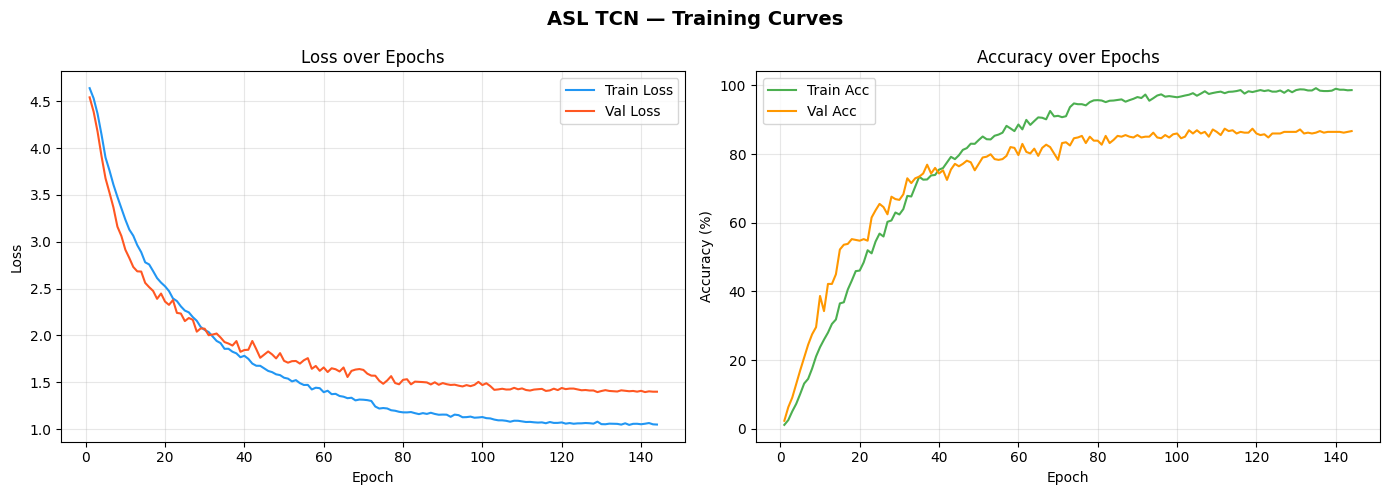

Total epochs trained : 144
Best val loss        : 1.3945 (epoch 129)
Best val acc         : 87.41% (epoch 112)


In [3]:
# Load training log
TRAINING_LOG = PROJECT_ROOT / 'models/asl_training_log.csv'

if TRAINING_LOG.exists():
    log_df = pd.read_csv(TRAINING_LOG)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('ASL TCN — Training Curves', fontsize=14, fontweight='bold')

    # Loss
    axes[0].plot(log_df['epoch'], log_df['train_loss'], label='Train Loss', color='#2196F3')
    axes[0].plot(log_df['epoch'], log_df['val_loss'],   label='Val Loss',   color='#FF5722')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Loss over Epochs')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Accuracy
    axes[1].plot(log_df['epoch'], log_df['train_acc'], label='Train Acc', color='#4CAF50')
    axes[1].plot(log_df['epoch'], log_df['val_acc'],   label='Val Acc',   color='#FF9800')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy (%)')
    axes[1].set_title('Accuracy over Epochs')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'asl_training_curves.png', dpi=150, bbox_inches='tight')
    plt.show()

    print(f'Total epochs trained : {len(log_df)}')
    print(f'Best val loss        : {log_df["val_loss"].min():.4f} (epoch {log_df["val_loss"].idxmin()+1})')
    print(f'Best val acc         : {log_df["val_acc"].max():.2f}% (epoch {log_df["val_acc"].idxmax()+1})')
else:
    print('[info] Training log not found — skipping training curves.')

## 4. Test Set Evaluation

In [35]:
class TestDataset(Dataset):
    def __init__(self, features_dir, manifest_csv):
        self.samples = []
        with open(manifest_csv, encoding='utf-8-sig') as f:
            for row in csv.DictReader(f):
                npy_path = features_dir / row['npy_file']
                if npy_path.exists():
                    self.samples.append((npy_path, int(row['label_id']), row['gloss']))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        npy_path, label_id, gloss = self.samples[idx]
        seq = np.load(str(npy_path)).astype(np.float32)
        return torch.from_numpy(seq), torch.tensor(label_id, dtype=torch.long), gloss

def collate_fn(batch):
    seqs   = torch.stack([b[0] for b in batch])
    labels = torch.stack([b[1] for b in batch])
    glosses = [b[2] for b in batch]
    return seqs, labels, glosses

# Load label map
label_map = {}
with open(LABEL_MAP, encoding='utf-8-sig') as f:
    for row in csv.DictReader(f):
        label_map[int(row['label_id'])] = row['gloss']
class_names = [label_map[i] for i in range(len(label_map))]

# Run inference
test_dataset = TestDataset(TEST_DIR, TEST_MANIFEST)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE,
                          shuffle=False, collate_fn=collate_fn)

all_preds, all_labels, all_glosses = [], [], []
with torch.no_grad():
    for x, y, glosses in test_loader:
        x = x.to(device)
        logits = model(x)
        preds  = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(y.numpy())
        all_glosses.extend(glosses)

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

# Overall metrics
acc  = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds, average='macro', zero_division=0)
rec  = recall_score(all_labels, all_preds, average='macro', zero_division=0)
f1   = f1_score(all_labels, all_preds, average='macro', zero_division=0)

print('=' * 50)
print('OVERALL TEST RESULTS')
print('=' * 50)
print(f'  Test samples : {len(all_labels)}')
print(f'  Accuracy     : {acc*100:.2f}%')
print(f'  Precision    : {prec*100:.2f}%  (macro)')
print(f'  Recall       : {rec*100:.2f}%  (macro)')
print(f'  F1 Score     : {f1*100:.2f}%  (macro)')


OVERALL TEST RESULTS
  Test samples : 1446
  Accuracy     : 80.43%
  Precision    : 81.81%  (macro)
  Recall       : 80.62%  (macro)
  F1 Score     : 80.38%  (macro)


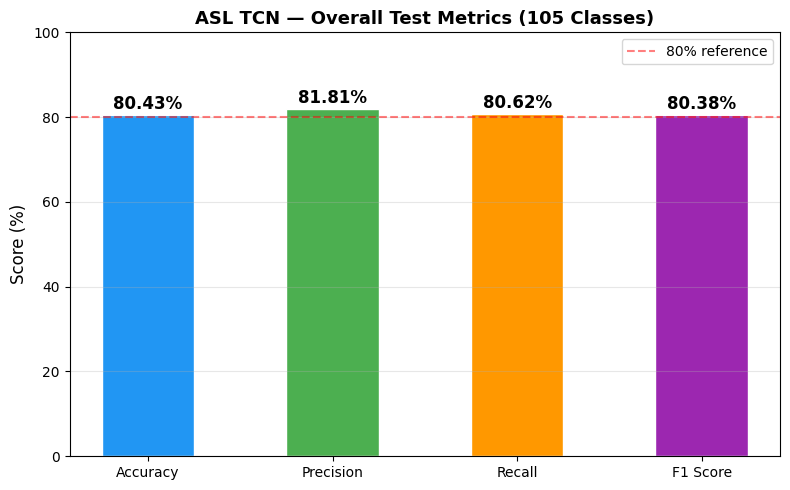

In [36]:
# Summary metrics bar chart
metrics = {
    'Accuracy':  acc * 100,
    'Precision': prec * 100,
    'Recall':    rec * 100,
    'F1 Score':  f1 * 100,
}

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(metrics.keys(), metrics.values(),
              color=['#2196F3', '#4CAF50', '#FF9800', '#9C27B0'],
              edgecolor='white', width=0.5)

for bar, val in zip(bars, metrics.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{val:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=12)

ax.set_ylim(0, 100)
ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('ASL TCN — Overall Test Metrics (105 Classes)', fontsize=13, fontweight='bold')
ax.axhline(y=80, color='red', linestyle='--', alpha=0.5, label='80% reference')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR/'asl_overall_metrics.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Per-Class Accuracy

In [37]:
# Per-class accuracy
per_class = defaultdict(lambda: {'correct': 0, 'total': 0})
for pred, label in zip(all_preds, all_labels):
    per_class[label]['total']   += 1
    if pred == label:
        per_class[label]['correct'] += 1

class_acc = []
for class_id in range(len(label_map)):
    total   = per_class[class_id]['total']
    correct = per_class[class_id]['correct']
    acc_c   = correct / total if total > 0 else 0.0
    class_acc.append((class_names[class_id], acc_c * 100, correct, total))

class_acc_df = pd.DataFrame(class_acc, columns=['gloss', 'accuracy', 'correct', 'total'])
class_acc_df = class_acc_df.sort_values('accuracy', ascending=False)

print(f'Classes at 100%  : {(class_acc_df["accuracy"] == 100).sum()}')
print(f'Classes above 80%: {(class_acc_df["accuracy"] >= 80).sum()}')
print(f'Classes above 60%: {(class_acc_df["accuracy"] >= 60).sum()}')
print(f'Classes below 50%: {(class_acc_df["accuracy"] < 50).sum()}')
print(f'Avg class accuracy: {class_acc_df["accuracy"].mean():.2f}%')


Classes at 100%  : 13
Classes above 80%: 63
Classes above 60%: 93
Classes below 50%: 3
Avg class accuracy: 80.62%


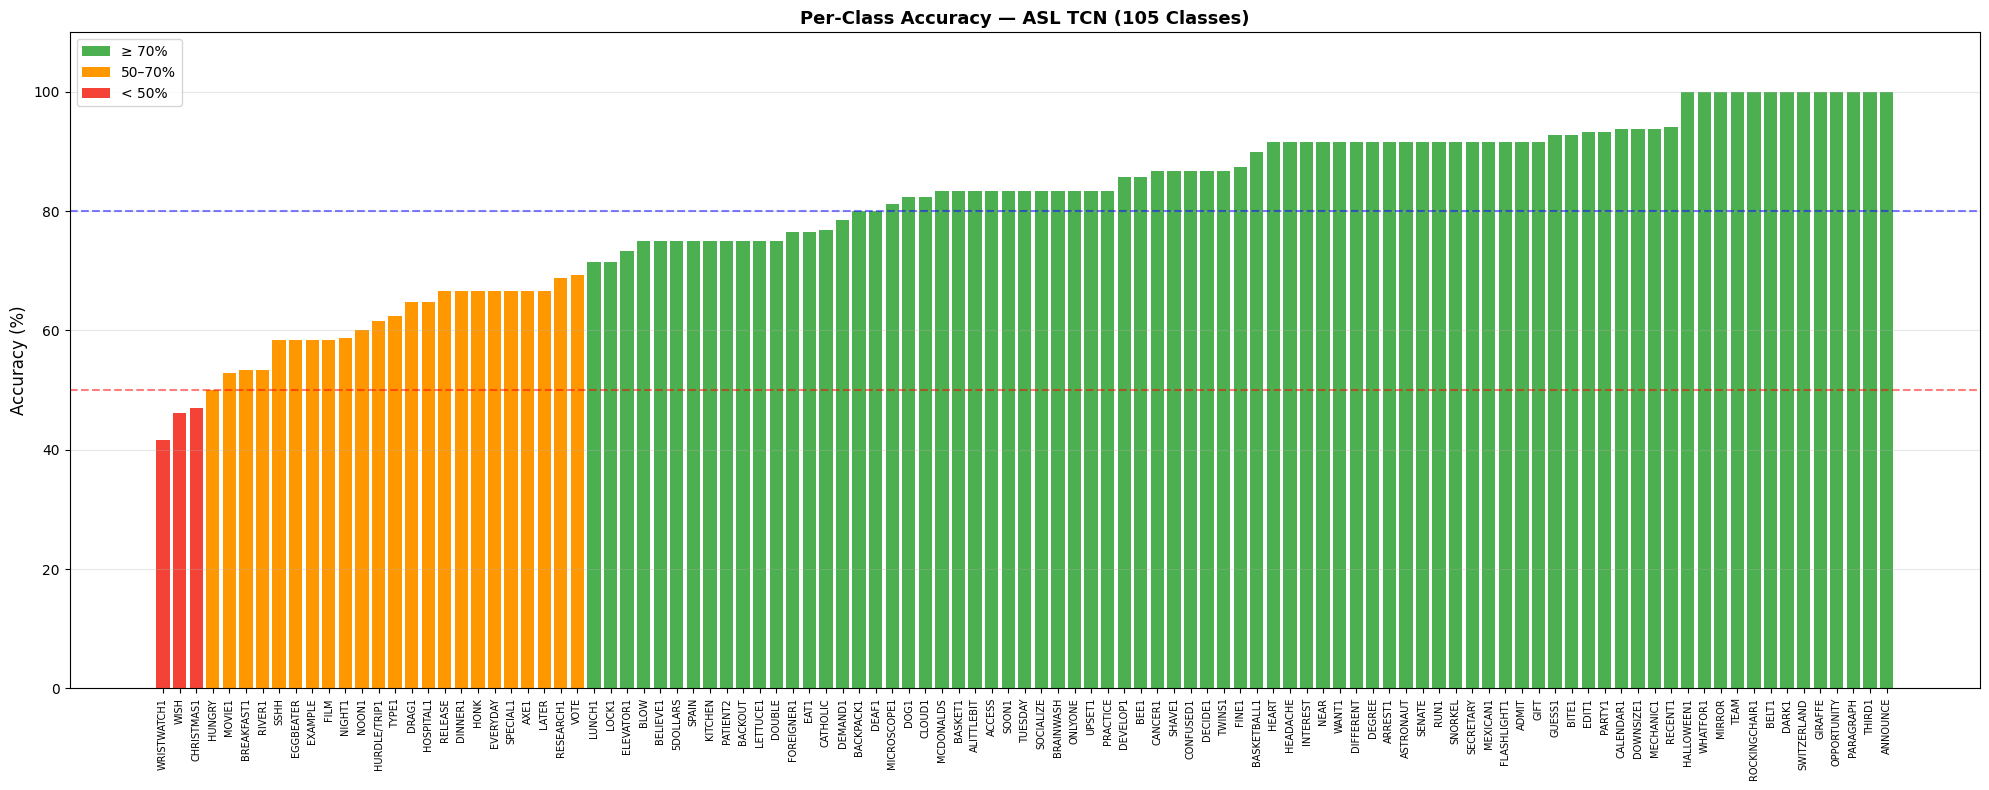

In [38]:
# Per-class accuracy bar chart — sorted
df_sorted = class_acc_df.sort_values('accuracy')

colors = ['#f44336' if a < 50 else '#FF9800' if a < 70 else '#4CAF50'
          for a in df_sorted['accuracy']]

fig, ax = plt.subplots(figsize=(20, 8))
bars = ax.bar(range(len(df_sorted)), df_sorted['accuracy'],
              color=colors, edgecolor='none', width=0.8)

ax.set_xticks(range(len(df_sorted)))
ax.set_xticklabels(df_sorted['gloss'], rotation=90, fontsize=7)
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('Per-Class Accuracy — ASL TCN (105 Classes)', fontsize=13, fontweight='bold')
ax.axhline(y=80, color='blue', linestyle='--', alpha=0.5, label='80%')
ax.axhline(y=50, color='red',  linestyle='--', alpha=0.5, label='50%')
ax.set_ylim(0, 110)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)

# Color legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#4CAF50', label='≥ 70%'),
    Patch(facecolor='#FF9800', label='50–70%'),
    Patch(facecolor='#f44336', label='< 50%'),
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=10)

plt.tight_layout()
plt.savefig(OUTPUT_DIR/'asl_per_class_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()


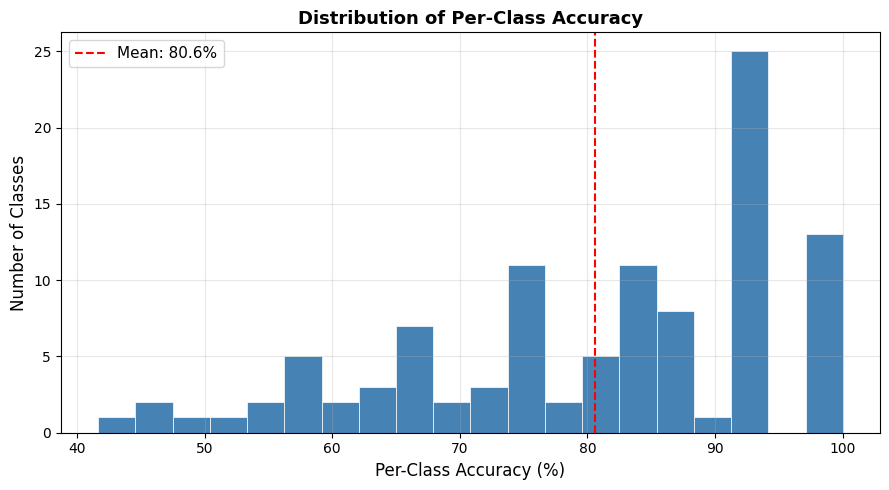

In [39]:
# Accuracy distribution histogram
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(class_acc_df['accuracy'], bins=20, color='steelblue',
        edgecolor='white', linewidth=0.5)
ax.axvline(class_acc_df['accuracy'].mean(), color='red', linestyle='--',
           label=f'Mean: {class_acc_df["accuracy"].mean():.1f}%')
ax.set_xlabel('Per-Class Accuracy (%)', fontsize=12)
ax.set_ylabel('Number of Classes', fontsize=12)
ax.set_title('Distribution of Per-Class Accuracy', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'asl_accuracy_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Confusion Matrix

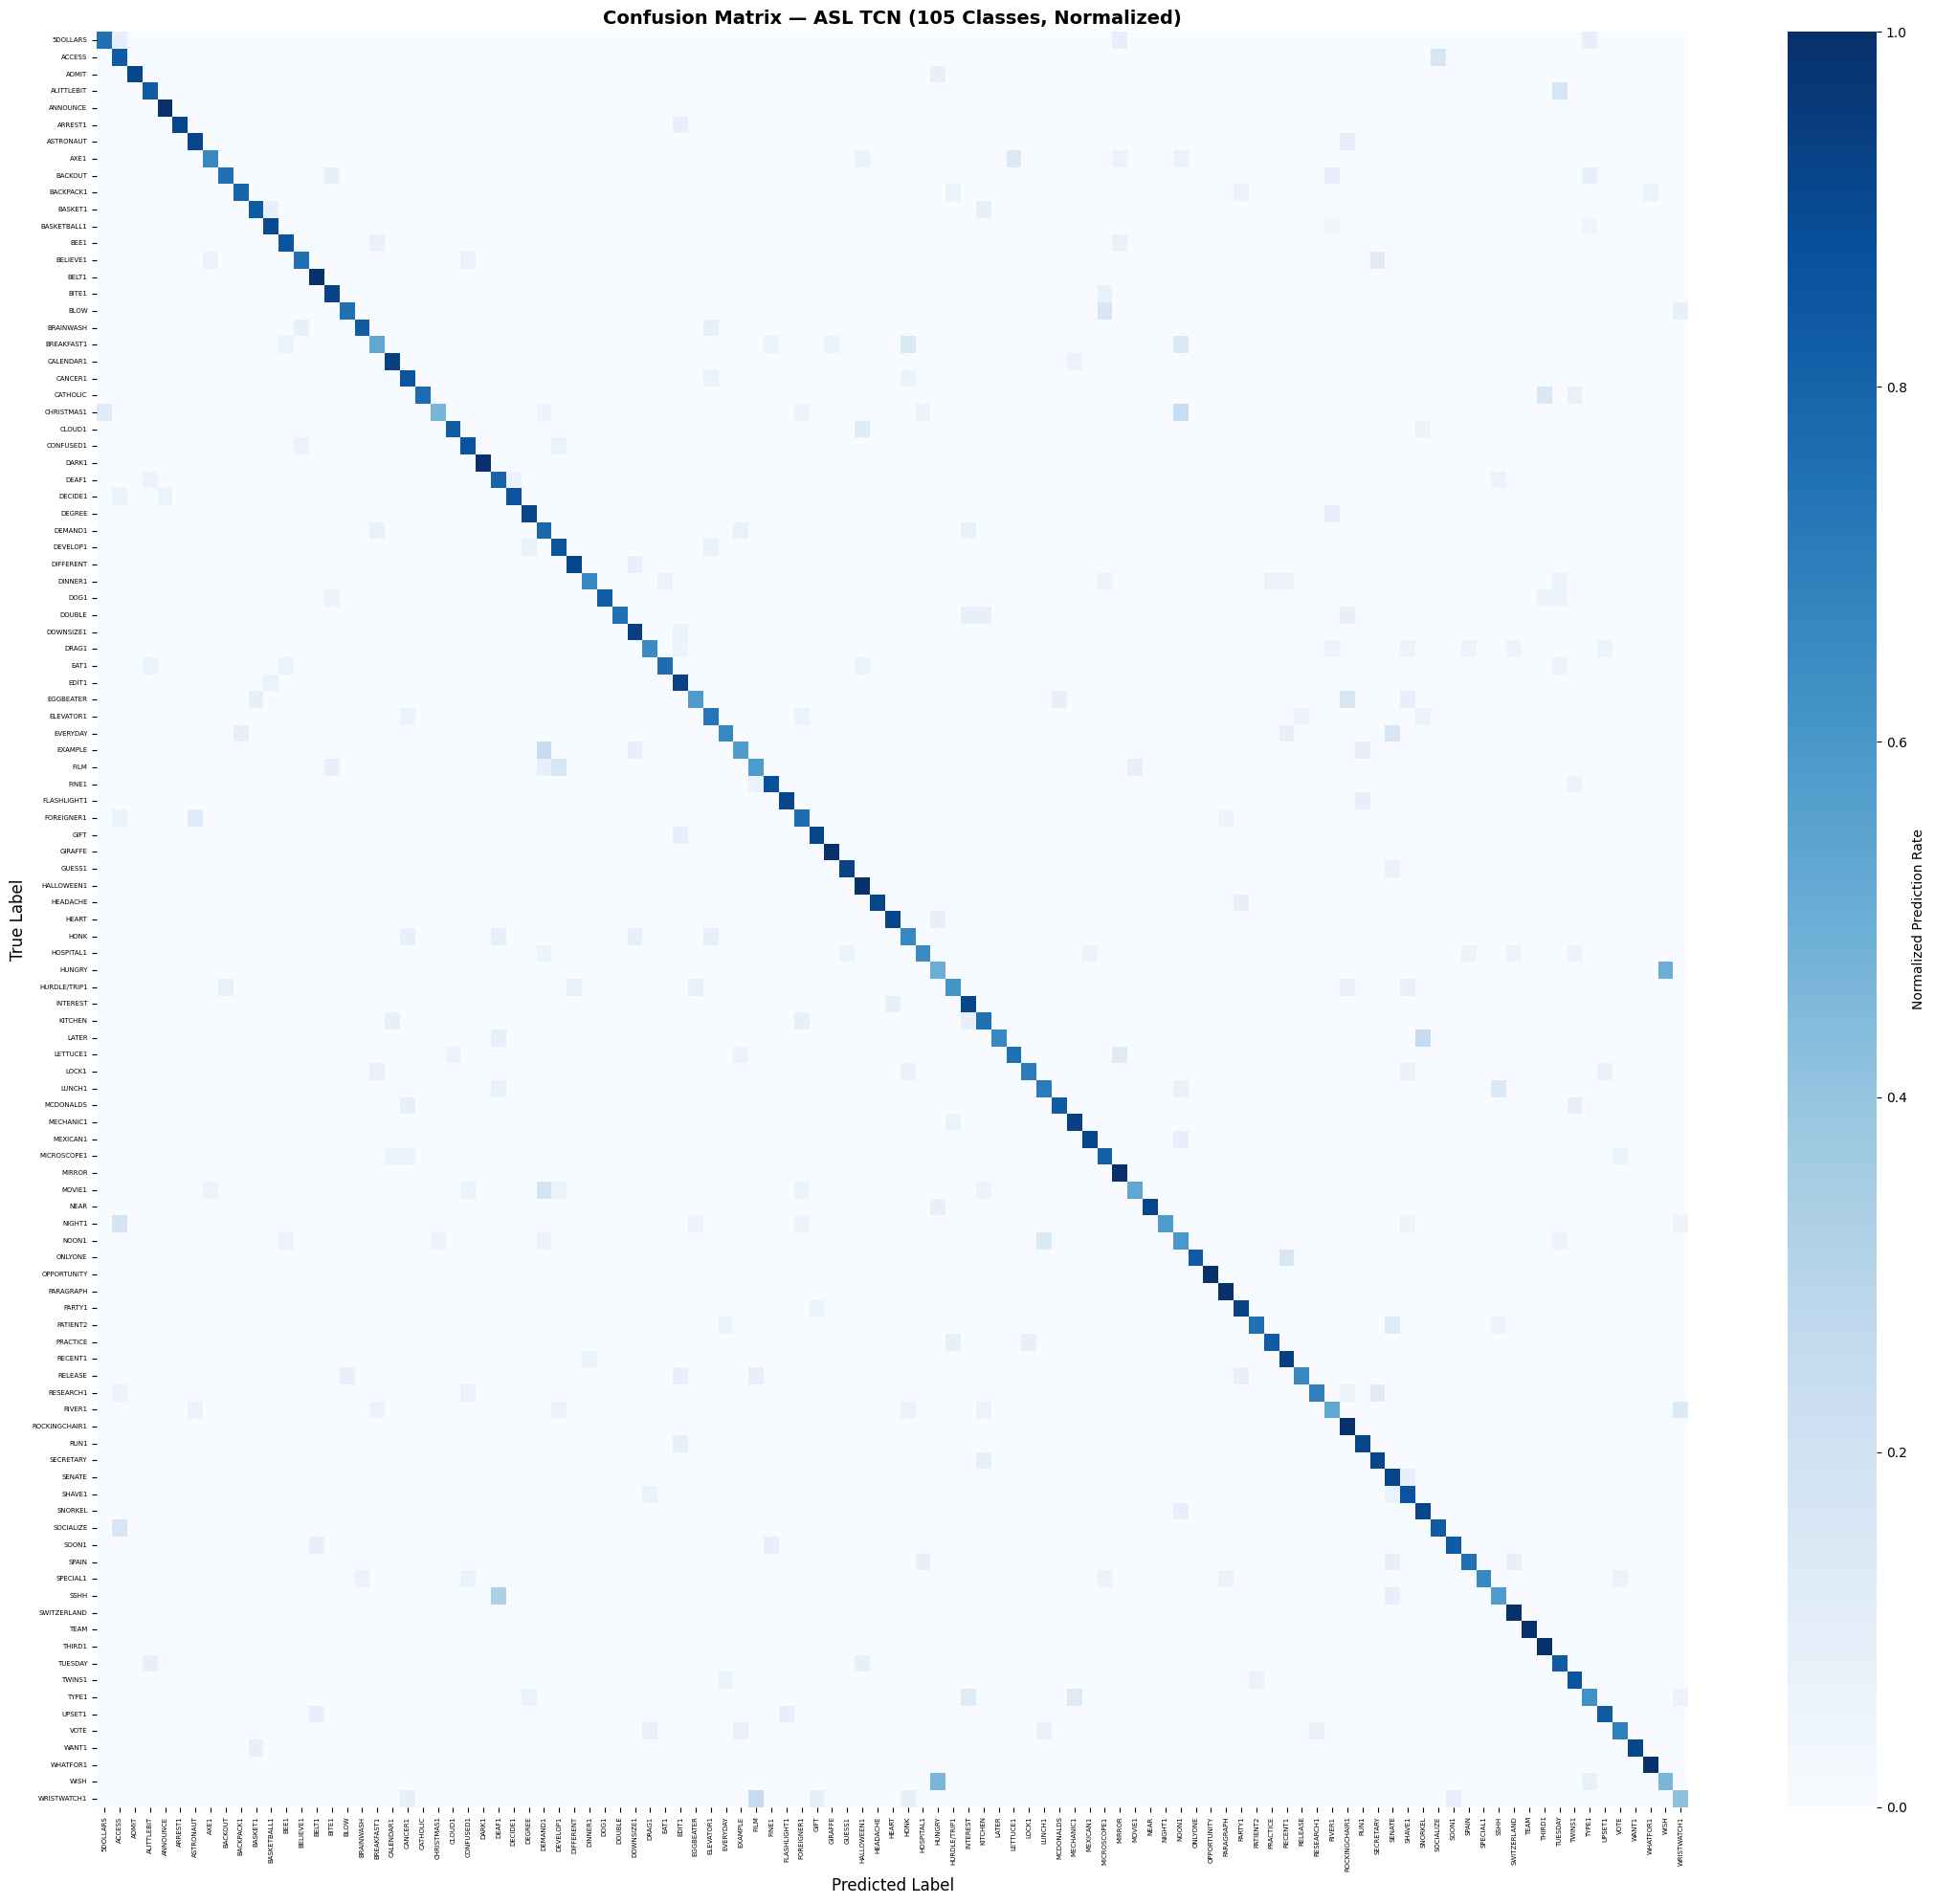

Full confusion matrix saved.


In [40]:
# Full 105x105 confusion matrix
cm = confusion_matrix(all_labels, all_preds, labels=list(range(len(label_map))))

# Normalize by row (true label)
cm_norm = cm.astype(float)
row_sums = cm.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1
cm_norm = cm_norm / row_sums

fig, ax = plt.subplots(figsize=(22, 20))
sns.heatmap(
    cm_norm,
    xticklabels=class_names,
    yticklabels=class_names,
    cmap='Blues',
    vmin=0, vmax=1,
    ax=ax,
    cbar_kws={'label': 'Normalized Prediction Rate'},
    linewidths=0,
)
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
ax.set_title('Confusion Matrix — ASL TCN (105 Classes, Normalized)', fontsize=14, fontweight='bold')
ax.tick_params(axis='x', labelsize=5, rotation=90)
ax.tick_params(axis='y', labelsize=5, rotation=0)

plt.tight_layout()
plt.savefig(OUTPUT_DIR/'asl_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Full confusion matrix saved.')


In [41]:
# Top 20 worst confused pairs
confused_pairs = []
for i in range(len(label_map)):
    for j in range(len(label_map)):
        if i != j and cm[i][j] > 0:
            confused_pairs.append({
                'True':      class_names[i],
                'Predicted': class_names[j],
                'Count':     int(cm[i][j]),
                'Error Rate': f"{cm[i][j]/cm[i].sum()*100:.1f}%"
            })
confused_pairs.sort(key=lambda x: x['Count'], reverse=True)

confused_df = pd.DataFrame(confused_pairs[:20])
print('TOP 20 MOST CONFUSED SIGN PAIRS')
print(confused_df.to_string(index=False))


TOP 20 MOST CONFUSED SIGN PAIRS
       True     Predicted  Count Error Rate
     HUNGRY          WISH      6      50.0%
       WISH        HUNGRY      6      46.2%
 CHRISTMAS1         NOON1      4      23.5%
       SSHH         DEAF1      4      33.3%
    EXAMPLE       DEMAND1      3      25.0%
      LATER       SNORKEL      3      25.0%
     MOVIE1       DEMAND1      3      17.6%
     NIGHT1        ACCESS      3      17.6%
WRISTWATCH1          FILM      3      25.0%
     ACCESS     SOCIALIZE      2      16.7%
 ALITTLEBIT       TUESDAY      2      16.7%
       AXE1      LETTUCE1      2      13.3%
   BELIEVE1     SECRETARY      2      12.5%
       BLOW   MICROSCOPE1      2      16.7%
 BREAKFAST1          HONK      2      13.3%
 BREAKFAST1         NOON1      2      13.3%
   CATHOLIC        THIRD1      2      15.4%
 CHRISTMAS1      5DOLLARS      2      11.8%
     CLOUD1    HALLOWEEN1      2      11.8%
  EGGBEATER ROCKINGCHAIR1      2      16.7%


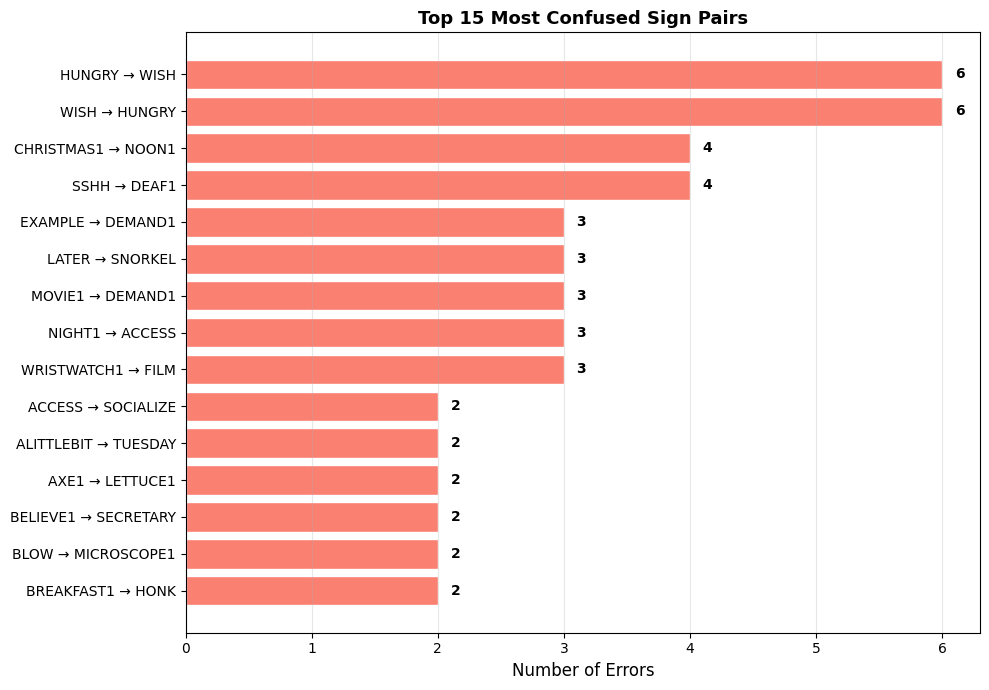

In [42]:
# Top confused pairs bar chart
top_pairs = confused_pairs[:15]
labels_pairs = [f"{p['True']} → {p['Predicted']}" for p in top_pairs]
counts = [p['Count'] for p in top_pairs]

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(labels_pairs[::-1], counts[::-1], color='salmon', edgecolor='white')
for bar, count in zip(bars, counts[::-1]):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
            str(count), va='center', fontsize=10, fontweight='bold')
ax.set_xlabel('Number of Errors', fontsize=12)
ax.set_title('Top 15 Most Confused Sign Pairs', fontsize=13, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'asl_confused_pairs.png', dpi=150, bbox_inches='tight')
plt.show()


## 7. Best and Worst Performing Classes

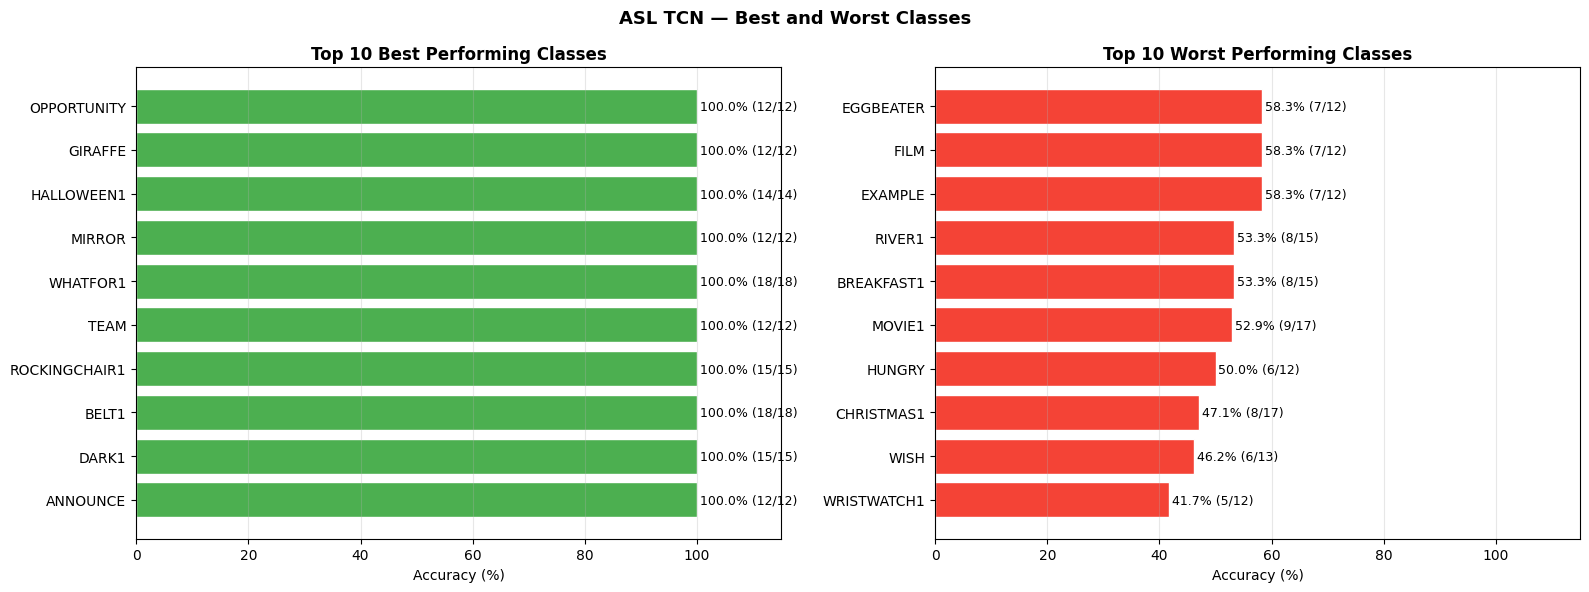

In [43]:
# Top 10 best and worst classes
best  = class_acc_df.head(10)
worst = class_acc_df.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Best
axes[0].barh(best['gloss'], best['accuracy'], color='#4CAF50', edgecolor='white')
for i, (acc, correct, total) in enumerate(zip(best['accuracy'], best['correct'], best['total'])):
    axes[0].text(acc + 0.5, i, f'{acc:.1f}% ({correct}/{total})',
                 va='center', fontsize=9)
axes[0].set_xlim(0, 115)
axes[0].set_xlabel('Accuracy (%)')
axes[0].set_title('Top 10 Best Performing Classes', fontweight='bold')
axes[0].grid(axis='x', alpha=0.3)

# Worst
worst_sorted = worst.sort_values('accuracy')
axes[1].barh(worst_sorted['gloss'], worst_sorted['accuracy'],
             color='#f44336', edgecolor='white')
for i, (acc, correct, total) in enumerate(zip(
        worst_sorted['accuracy'], worst_sorted['correct'], worst_sorted['total'])):
    axes[1].text(acc + 0.5, i, f'{acc:.1f}% ({correct}/{total})',
                 va='center', fontsize=9)
axes[1].set_xlim(0, 115)
axes[1].set_xlabel('Accuracy (%)')
axes[1].set_title('Top 10 Worst Performing Classes', fontweight='bold')
axes[1].grid(axis='x', alpha=0.3)

plt.suptitle('ASL TCN — Best and Worst Classes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'asl_best_worst_classes.png', dpi=150, bbox_inches='tight')
plt.show()


## 8. Summary Table

In [44]:
# Final summary
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

_acc  = accuracy_score(all_labels, all_preds)
_prec = precision_score(all_labels, all_preds, average='macro', zero_division=0)
_rec  = recall_score(all_labels, all_preds, average='macro', zero_division=0)
_f1   = f1_score(all_labels, all_preds, average='macro', zero_division=0)

summary = {
    'Metric': [
        'Dataset', 'Number of Classes', 'Train Sequences', 'Val Sequences',
        'Test Sequences', 'Feature Dimension', 'Sequence Length',
        'Model', 'Parameters', 'Best Epoch',
        'Test Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1',
        'Best Class Accuracy', 'Worst Class Accuracy', 'Classes at 100%', 'Classes below 50%'
    ],
    'Value': [
        'ASL Citizen (Selected)', '105', str(len(train_manifest)),
        str(len(val_manifest)), str(len(test_manifest)),
        '302', '64 frames',
        'TCN (4 blocks: 64→128→128→256)', '602,281',
        str(checkpoint['epoch']),
        f"{_acc*100:.2f}%",
        f"{_prec*100:.2f}%",
        f"{_rec*100:.2f}%",
        f"{_f1*100:.2f}%",
        f"{class_acc_df['accuracy'].max():.1f}%",
        f"{class_acc_df['accuracy'].min():.1f}%",
        str((class_acc_df['accuracy'] == 100).sum()),
        str((class_acc_df['accuracy'] < 50).sum()),
    ]
}

summary_df = pd.DataFrame(summary)
print('ASL TCN — FINAL RESULTS SUMMARY')
print('=' * 45)
for _, row in summary_df.iterrows():
    print(f"  {row['Metric']:<25} {row['Value']}")


ASL TCN — FINAL RESULTS SUMMARY
  Dataset                   ASL Citizen (Selected)
  Number of Classes         105
  Train Sequences           1775
  Val Sequences             429
  Test Sequences            1446
  Feature Dimension         302
  Sequence Length           64 frames
  Model                     TCN (4 blocks: 64→128→128→256)
  Parameters                602,281
  Best Epoch                129
  Test Accuracy             80.43%
  Macro Precision           81.81%
  Macro Recall              80.62%
  Macro F1                  80.38%
  Best Class Accuracy       100.0%
  Worst Class Accuracy      41.7%
  Classes at 100%           13
  Classes below 50%         3


## 9. Classification Report

In [45]:
# Full classification report
report = classification_report(
    all_labels, all_preds,
    target_names=class_names,
    zero_division=0
)
print(report)

# Save to text file
with open(OUTPUT_DIR/'asl_classification_report.txt', 'w') as f:
    f.write('ASL TCN Classification Report\n')
    f.write('=' * 60 + '\n')
    f.write(report)
print('Classification report saved to asl_classification_report.txt')


               precision    recall  f1-score   support

     5DOLLARS       0.82      0.75      0.78        12
       ACCESS       0.53      0.83      0.65        12
        ADMIT       1.00      0.92      0.96        12
   ALITTLEBIT       0.77      0.83      0.80        12
     ANNOUNCE       0.92      1.00      0.96        12
      ARREST1       1.00      0.92      0.96        12
    ASTRONAUT       0.79      0.92      0.85        12
         AXE1       0.83      0.67      0.74        15
      BACKOUT       0.90      0.75      0.82        12
    BACKPACK1       0.92      0.80      0.86        15
      BASKET1       0.83      0.83      0.83        12
  BASKETBALL1       0.90      0.90      0.90        20
         BEE1       0.80      0.86      0.83        14
     BELIEVE1       0.86      0.75      0.80        16
        BELT1       0.90      1.00      0.95        18
        BITE1       0.81      0.93      0.87        14
         BLOW       0.90      0.75      0.82        12
    BRAIN